In [ ]:
#Install the requested libraries:
#--------------------------------
# !pip install pandas
# !pip install BERTopic
# !pip install matplotlib
# !pip install requests


[notice] A new release of pip is available: 25.1.1 -> 26.3
[notice] To update, run: pip install --upgrade pip


In [1]:
import pandas as pd
import re
import pickle
from datetime import datetime
from bertopic import BERTopic

/Users/anajaramillo/Dropbox/Post-docs/1. Post-doc Mammoth/18. Peace research/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
W1110 14:59:46.088000 93117 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


In [2]:
# !pip install pandas
import matplotlib.pyplot as plt
import networkx as nx
import requests
import numpy as np
# import networks_layouts
from matplotlib import colors
import pickle

import ast
def convert_str_to_list(x):
    try:
        return ast.literal_eval(x, '|')
    except:
        return None
def read_pickle(file_name):
    '''Function to read pickles faster'''
    pickle_in = open(file_name, 'rb')
    variable = pickle.load(pickle_in)
    return variable

def write_pickle(variable, file_name):
    '''Function to write pickles faster'''
    pickle_out = open(file_name, 'wb')
    pickle.dump(variable, pickle_out)

#Move all files of one folder to another one:
from os import listdir
from os.path import isfile, join
import os
import shutil

#Read all the files with multiple languages:
folder = 'Multi-lingual-data/'
onlyfiles = [f for f in listdir(folder) if '.csv' in f]
len(onlyfiles)

64

In [ ]:
Filtered_DataFrame_out_filt = read_pickle('Filtered_DataFrame_out_filt.pkl')
Filtered_DataFrame_out_filt_2 = Filtered_DataFrame_out_filt.drop_duplicates('abstract')
Filtered_DataFrame_out_filt_2.detected_language.value_counts()

findfont: Failed to find font weight light for DejaVu Sans, now using 400.


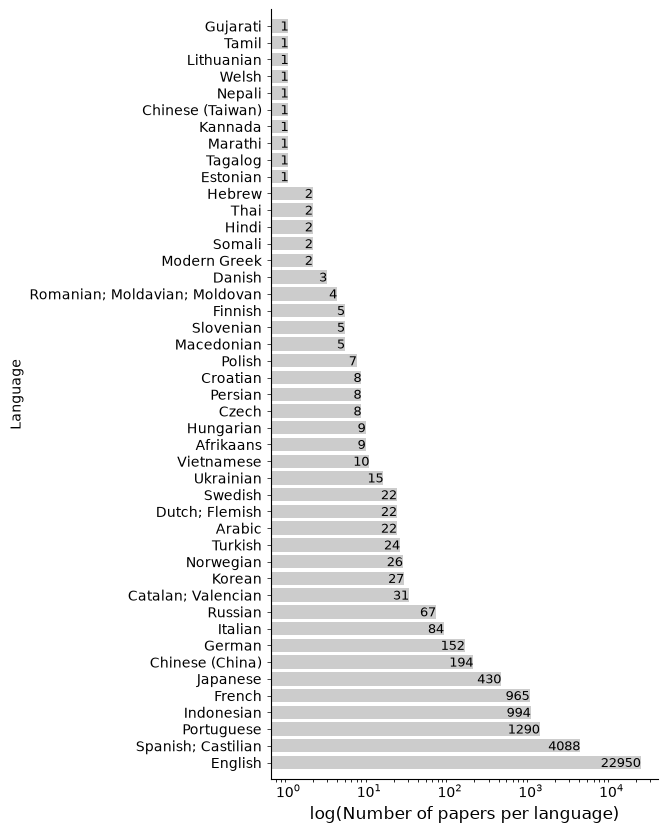

In [58]:
#Downloaded from here: 'https://datahub.io/core/language-codes'
language_codes = pd.read_csv('language-codes.csv')
ncols = 1
nrows = 1
fig, ax = plt.subplots(ncols=ncols, nrows=nrows,figsize=(5*ncols,10*nrows), sharex= True, sharey= True,
                       gridspec_kw={'width_ratios': ncols*[0.5], 'height_ratios': nrows*[0.8]})

language = [language_codes[language_codes.alpha2==l].English.iloc[0] for l in list(dict(Filtered_DataFrame_out_filt_2.detected_language.value_counts()).keys())]
number_papers = list(dict(Filtered_DataFrame_out_filt_2.detected_language.value_counts()).values())
x,y = language,number_papers

ax.barh(x, y, height=0.8, color='black', alpha=0.2)
ax.set_xscale('log')
ax.set_ylim(-1,45)
# ax.set_ylim(0.00001,1.1)


# ax[row_plt].yaxis.set_major_locator(plt.MaxNLocator(5))

ax.tick_params('y', size=0, colors="black", labelsize=10)
ax.tick_params('x', size=0, colors="black", labelsize=10)
ax.set_ylabel('Language',  size=10)

for i,value in enumerate(number_papers):
    ax.text(value, i-0.45, value, horizontalalignment='right',
                    verticalalignment='bottom',weight="light",
                    fontsize=9, rotation='horizontal')
    
ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)
ax.yaxis.set_ticks_position('left')
ax.xaxis.set_ticks_position('bottom')

# ax[row_plt].xaxis.set_tick_params(width=1, length=2)
ax.yaxis.set_tick_params(width=0.5, length=3)
ax.set_xlabel('log(Number of papers per language)',  size=12)

plt.subplots_adjust(hspace=0.5)
# plt.savefig("Average_citations_per_year_"+t1+".pdf", bbox_inches='tight')
plt.show()

In [ ]:
#Select a random number of papers that were half of them at least with 2 of the terms 
in the 0.65 threshold. And make it for the top 5 languages.
term = 'Decolonial peace'
Filtered_DataFrame_out_filt_2[(Filtered_DataFrame_out_filt_2['Probability_term_'+term].apply(lambda x: x[0]>=0.6))| (Filtered_DataFrame_out_filt_2['Appearance_term_'+term]=='Yes')].detected_language.value_counts()

detected_language
en    157
es     40
pt     16
fr      7
id      2
ca      1
Name: count, dtype: int64

In [ ]:
import random

#to create the lists of random terms:
languages_to_check = ['id']
dict_file_language = dict()
for l in languages_to_check:
    print(l)
    #Filter for the needed terms:
    Filtered_language_detected = Filtered_DataFrame_out_filt_2[(Filtered_DataFrame_out_filt_2.detected_language==l) & (Filtered_DataFrame_out_filt_2['Probability_term_'+term].apply(lambda x: x[0]>=0.6) | (Filtered_DataFrame_out_filt_2['Appearance_term_'+term]=='Yes'))]
    Filtered_language_non_detected = Filtered_DataFrame_out_filt_2[(Filtered_DataFrame_out_filt_2.detected_language==l) & ( Filtered_DataFrame_out_filt_2['Probability_term_'+term].apply(lambda x: x[0]<0.6) & (Filtered_DataFrame_out_filt_2['Appearance_term_'+term]=='No'))]

    #select a random sample and save it in an csv file:
    ar_non=random.sample(range(Filtered_language_non_detected.shape[0]),8)
    ar=random.sample(range(Filtered_language_detected.shape[0]),2)
    
    dict_file_language[l] = pd.concat([Filtered_language_non_detected.iloc[ar_non][['id','abstract']], Filtered_language_detected.iloc[ar][['id','abstract']]], axis=0)
    
    dict_file_language[l].to_csv('Filtered_language_non_detected_'+term+'_'+l+'.csv', sep='|', index=None)

id
